# CLV — next-90-day purchase revenue
Train on raw Online Retail II. Processed Retail is used only for compatibility checks.
Predict positive purchase revenue in GBP before refunds for existing customers. This is not profit, unlimited lifetime value, a probability, or guaranteed spending. Historical giftware/wholesale data supports the project demo; performance on other stores is not established.
Run top to bottom. Outputs: this notebook and backend/ml_models/clv_model.pkl. No downloads, dataset changes or Git actions.

## Executed result and review notes

All code cells ran successfully on the local raw and processed Retail files. Selected by validation MAE: **Random Forest**, 150 trees, minimum leaf size 5, all 11 candidate features retained (all had positive validation permutation importance).

- Fixed history: **288 days**; three training cutoffs, one validation cutoff and one final test cutoff.
- Validation MAE: **GBP 355.00** versus baseline **GBP 380.03**.
- Test MAE: **GBP 573.22** versus baseline **GBP 544.66**. Test RMSE: **GBP 2,826.17**; R²: **0.510**.
- Raw/processed feature, target and prediction comparisons passed at all six cutoffs; saved artifact reload passed.
- Latest historical scoring: **4,028** eligible customers; **1,914** explicitly marked insufficient history.
- **Artifact is experimental because it did not beat the test baseline. Do not activate it as a production model.** No settings were tuned to improve the observed test score.

Read-only synthetic checks also passed for complete invoice totals, half-open time boundaries, exclusion of future inputs, zero-spend outcomes, genuine zero interval variation versus undefined intervals, and invalid/accounting/manual record exclusions.

EDA revealed accounting/manual/test codes; the final run excludes those using identical raw and processed policies. An earlier development run used a broader positive-line definition; its test results were also observed. The corrected test metrics are therefore transparent development evidence, not a pristine external confirmation. A new untouched period or dataset is needed for subsequent model improvements and stronger readiness claims.

The first version evaluates numeric customer-history features. Country and product-description text are not empirically established to be useless; geographic/text feature modelling remains unevaluated rather than claimed irrelevant. No customer identities or purchase history were fabricated.


In [1]:
from pathlib import Path
from decimal import Decimal, InvalidOperation
import json, platform, hashlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
    if (p/'data_prep/raw/online-retail-ii-uci/online_retail_II.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the project or training folder; raw Retail CSV is required.')
RAW_PATH = ROOT/'data_prep/raw/online-retail-ii-uci/online_retail_II.csv'
PROCESSED = ROOT/'data_prep/processed/online-retail-ii-uci'
MODEL_PATH = ROOT/'backend/ml_models/clv_model.pkl'
SEED, HORIZON_DAYS, TOP_FRACTION = 42, 90, .20
sns.set_theme(style='whitegrid')
print('Project:', ROOT)
print('scikit-learn:', sklearn.__version__)
print('Target: next 90 days of positive purchase revenue, GBP, before returns.')

Project: D:\CDP -FYP
scikit-learn: 1.9.1
Target: next 90 days of positive purchase revenue, GBP, before returns.


## 1. Read raw data and perform EDA
Identifiers are read as strings. Inspect repeated lines and large purchases before making cleaning decisions.

In [2]:
raw = pd.read_csv(RAW_PATH, dtype=str, keep_default_na=False)
print('Shape:', raw.shape)
print('Columns:', raw.columns.tolist())
print(raw.head().to_string(index=False))
print('Read types:'); print(raw.dtypes.to_string())
print('Blank cells:'); print(raw.apply(lambda s:s.str.strip().eq('').sum()).to_string())
for c in ['Customer ID','Invoice','StockCode']:
    print('Distinct nonblank', c, ':', raw.loc[raw[c].str.strip().ne(''),c].nunique())
print('Exact repeated lines beyond first:', raw.duplicated().sum())
dates = pd.to_datetime(raw['InvoiceDate'], errors='coerce')
qty = pd.to_numeric(raw['Quantity'], errors='coerce')
price = pd.to_numeric(raw['Price'], errors='coerce')
print('Date range:', dates.min(), 'to', dates.max())
print('Cancellation lines:', raw['Invoice'].str.upper().str.startswith('C').sum())
print('Negative quantities:', qty.lt(0).sum())
print('Zero prices:', price.eq(0).sum(), '| Negative prices:', price.lt(0).sum())
print('Quantity distribution:'); print(qty.describe().to_string())
print('Price distribution:'); print(price.describe().to_string())
print('Most frequent stock codes:'); print(raw['StockCode'].value_counts().head(12).to_string())
print('Largest line amounts — inspect, do not automatically remove:')
print(raw.assign(amount=qty*price).nlargest(8,'amount')[
    ['Invoice','StockCode','Description','Quantity','Price','amount']].to_string(index=False))
print('Inspect nonnumeric-leading codes before defining exclusions:')
print(raw.loc[~raw['StockCode'].str.match(r'^\d')].groupby(['StockCode','Description']).size().sort_values(ascending=False).head(35).to_string())

Shape: (1067371, 8)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
Invoice StockCode                         Description Quantity         InvoiceDate Price Customer ID        Country
 489434     85048 15CM CHRISTMAS GLASS BALL 20 LIGHTS       12 2009-12-01 07:45:00  6.95     13085.0 United Kingdom
 489434    79323P                  PINK CHERRY LIGHTS       12 2009-12-01 07:45:00  6.75     13085.0 United Kingdom
 489434    79323W                 WHITE CHERRY LIGHTS       12 2009-12-01 07:45:00  6.75     13085.0 United Kingdom
 489434     22041        RECORD FRAME 7" SINGLE SIZE        48 2009-12-01 07:45:00   2.1     13085.0 United Kingdom
 489434     21232      STRAWBERRY CERAMIC TRINKET BOX       24 2009-12-01 07:45:00  1.25     13085.0 United Kingdom
Read types:
Invoice        str
StockCode      str
Description    str
Quantity       str
InvoiceDate    str
Price          str
Customer ID    str
Country        str
Blank cel

## 2. Prepare positive purchases and complete invoices
Exclude missing keys, invalid dates/numbers, cancellations, nonpositive quantities and nonpositive prices. These exclusions are model policy; the platform correctly preserves returns.
Retain repeated transaction lines and genuine large purchases. Do not guess that stock codes containing letters are invalid products. This first target includes valid positive invoice charges; product diversity counts distinct source stock codes.
Use decimal multiplication before conversion to floating-point model inputs. No currency conversion or early rounding.
Source inspection identifies bad-debt adjustments (B), adjustments (ADJUST/ADJUST2), fees/commission (BANK CHARGES/AMAZONFEE/CRUK), discounts (D), manual/unverified amounts (M), and explicit test records (TEST001/TEST002). Exclude these exact codes in both paths. Keep postage/carriage and genuine alphanumeric merchandise codes; do not filter all letter-prefixed codes.

Raw Retail | input: 1067371
  missing Customer ID : 243007
  missing Invoice : 0
  missing StockCode : 0
  accounting/manual/test code : 1857
  invalid date : 0
  invalid/nonintegral quantity : 0
  invalid price : 0
  cancellation : 19494
  nonpositive quantity : 22950
  nonpositive price : 6207
Distinct excluded rows: 262613 (reasons may overlap)
Retained purchase lines: 804758
Purchase invoices: 36711 | Purchasing customers: 5854
Invoice values:
count     36711.000000
mean        479.031629
std        1374.520745
min           0.380000
50%         305.400000
90%         849.940000
99%        3670.300000
max      168469.600000
Customer spending:
count      5854.000000
mean       3004.053664
std       14671.582826
min           2.950000
50%         899.215000
90%        5570.851000
99%       29187.944700
max      608821.650000
Top 1% customer revenue share: 0.3201904558941826


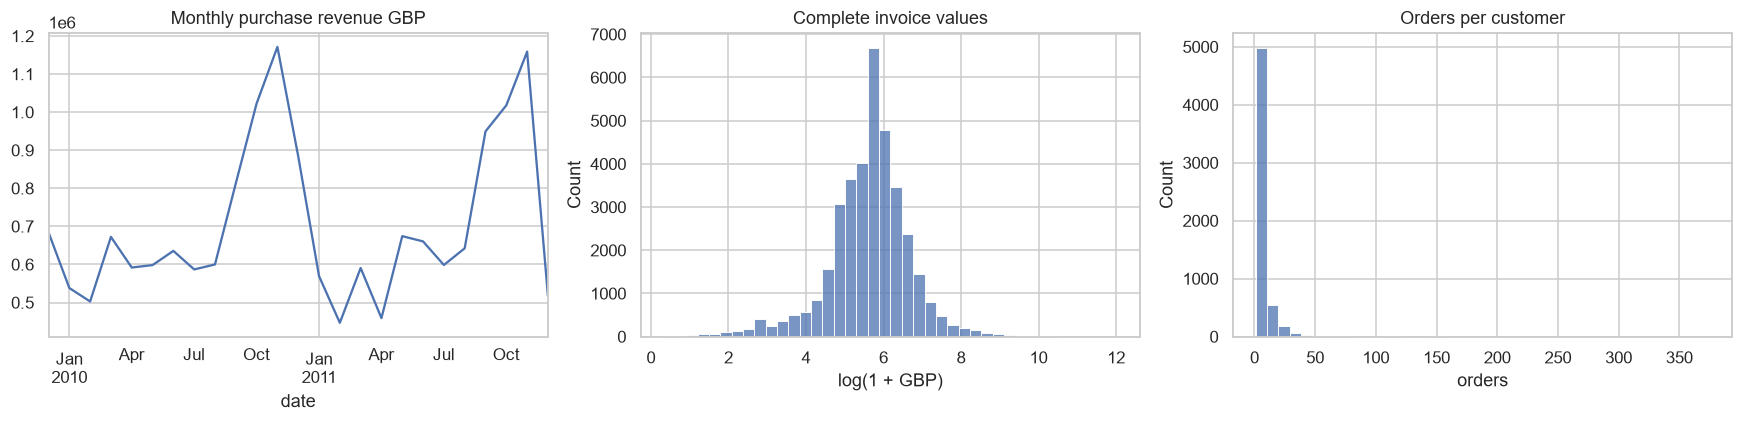

In [3]:
def money(value):
    try:
        number = Decimal(str(value).strip())
        return number if number.is_finite() else None
    except (InvalidOperation, ValueError):
        return None

def prepare_purchases(source, label):
    df = source.copy()
    nulls = {'','nan','none','null','<na>','nat'}
    for c in ['Customer ID','Invoice','StockCode']:
        df[c] = df[c].fillna('').astype(str).str.strip()
    df['timestamp'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
    df['quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
    decimal_prices = df['Price'].map(money)
    df['price'] = decimal_prices.map(lambda x:float(x) if x is not None else np.nan)
    reasons = {f'missing {c}':df[c].str.lower().isin(nulls)
               for c in ['Customer ID','Invoice','StockCode']}
    # Source descriptions identify accounting/test records, not merchandise purchases.
    excluded_codes = {'B','ADJUST','ADJUST2','BANK CHARGES','AMAZONFEE','CRUK','D','M','TEST001','TEST002'}
    reasons.update({
        'accounting/manual/test code':df['StockCode'].str.upper().isin(excluded_codes),
        'invalid date':df['timestamp'].isna(),
        'invalid/nonintegral quantity':~np.isfinite(df['quantity']) | df['quantity'].mod(1).ne(0),
        'invalid price':~np.isfinite(df['price']),
        'cancellation':df['Invoice'].str.upper().str.startswith('C'),
        'nonpositive quantity':df['quantity'].le(0),
        'nonpositive price':df['price'].le(0)})
    rejected = pd.DataFrame(reasons).any(axis=1)
    print(label, '| input:', len(df))
    for reason, mask in reasons.items():
        print(' ', reason, ':', int(mask.sum()))
    print('Distinct excluded rows:', int(rejected.sum()), '(reasons may overlap)')
    df = df.loc[~rejected].copy()
    df['revenue'] = [float(Decimal(str(q))*p)
        for q,p in zip(df['quantity'],decimal_prices.loc[df.index])]
    assert np.isfinite(df['revenue']).all()
    df['date'] = df['timestamp'].dt.normalize()
    check = df.groupby('Invoice').agg(customers=('Customer ID','nunique'), dates=('date','nunique'))
    if check.gt(1).any().any():
        raise ValueError('Conflicting customer/date within invoice; inspect before training.')
    print('Retained purchase lines:', len(df))
    return df[['Customer ID','Invoice','StockCode','date','quantity','price','revenue']]

purchases = prepare_purchases(raw,'Raw Retail')
orders = purchases.groupby(['Customer ID','Invoice','date'],as_index=False).agg(
    order_value=('revenue','sum'),items=('quantity','sum'))
summary = orders.groupby('Customer ID').agg(revenue=('order_value','sum'),orders=('Invoice','nunique'))
print('Purchase invoices:',len(orders),'| Purchasing customers:',len(summary))
print('Invoice values:'); print(orders['order_value'].describe(percentiles=[.5,.9,.99]).to_string())
print('Customer spending:'); print(summary['revenue'].describe(percentiles=[.5,.9,.99]).to_string())
print('Top 1% customer revenue share:',summary['revenue'].nlargest(
    max(1,int(np.ceil(.01*len(summary))))).sum()/summary['revenue'].sum())
fig,axes=plt.subplots(1,3,figsize=(16,4))
purchases.groupby(purchases['date'].dt.to_period('M'))['revenue'].sum().plot(ax=axes[0],title='Monthly purchase revenue GBP')
sns.histplot(np.log1p(orders['order_value']),bins=40,ax=axes[1])
axes[1].set(xlabel='log(1 + GBP)',title='Complete invoice values')
sns.histplot(summary['orders'],bins=40,ax=axes[2])
axes[2].set(title='Orders per customer')
plt.tight_layout(); plt.show()

## 3. Historical windows and feature engineering
History: [cutoff − history days, cutoff). Target: [cutoff, cutoff + 90 days).
Use source-local calendar days and historical observation dates. Conservatively omit the final potentially partial source day.
Choose up to 365 history days while leaving at least three training windows plus validation and test. Customers need at least one valid purchase in history; older inactive customers receive an explicit insufficient-history status.
Order values are complete invoice totals. Tenure means observed tenure within this history, not the customer's true lifetime.
Intervals include zero-day gaps for separate same-day invoices. Regularity uses sample standard deviation (ddof=1): fewer than two intervals is missing; sufficient equally spaced intervals can have genuine zero variance.

Exclusive complete-day endpoint: 2011-12-09 00:00:00
Fixed history days: 288
Training cutoffs: ['2010-09-15', '2010-12-14', '2011-03-14']
Validation: 2011-06-12 | Test: 2011-09-10
2010-09-15: history [2009-12-01, 2010-09-15); outcome [2010-09-15, 2010-12-14); customers=3,377; zero targets=42.5%
2010-12-14: history [2010-03-01, 2010-12-14); outcome [2010-12-14, 2011-03-14); customers=4,024; zero targets=68.4%
2011-03-14: history [2010-05-30, 2011-03-14); outcome [2011-03-14, 2011-06-12); customers=3,930; zero targets=60.9%
2011-06-12: history [2010-08-28, 2011-06-12); outcome [2011-06-12, 2011-09-10); customers=3,982; zero targets=62.0%
2011-09-10: history [2010-11-26, 2011-09-10); outcome [2011-09-10, 2011-12-09); customers=3,437; zero targets=43.7%
Training snapshots: 11331 | Unique customers: 4585
Feature samples:
             recency  frequency  monetary  avg_order_value  customer_tenure  total_items_bought  unique_products_bought  max_single_order_value  min_single_order_value  avg

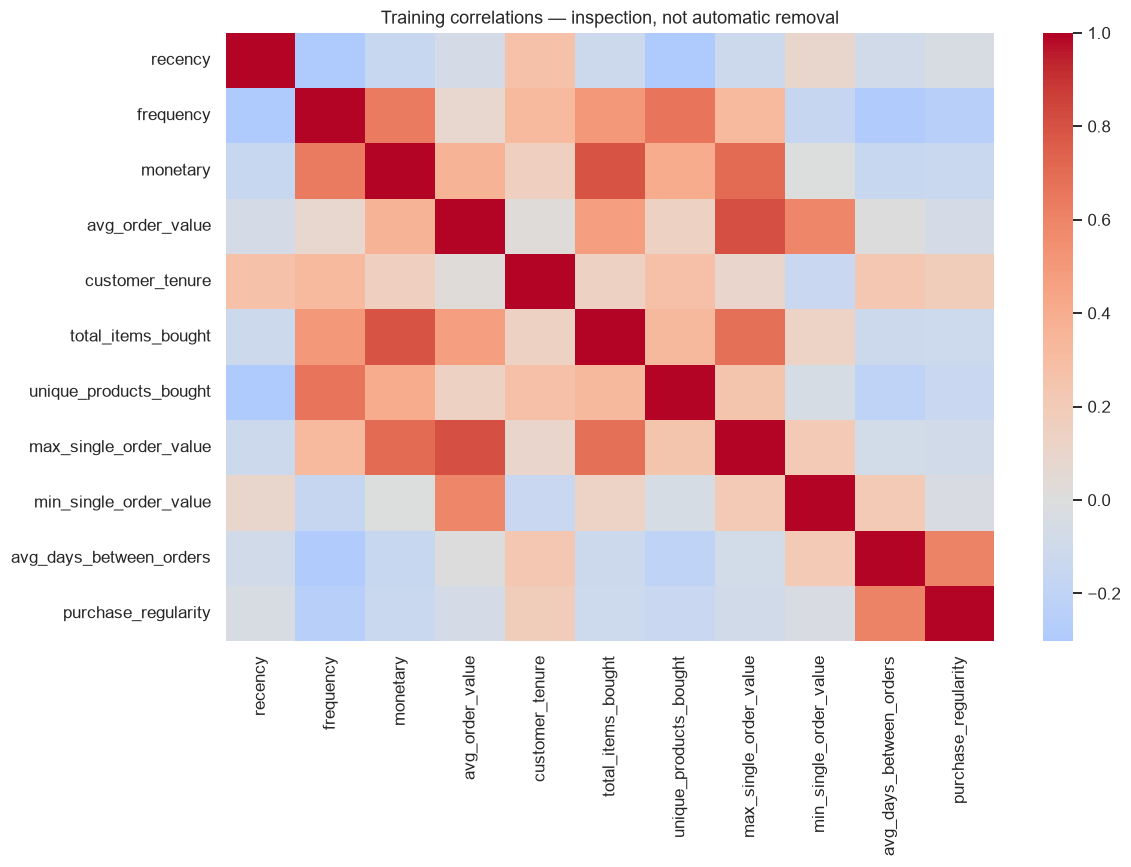

In [4]:
SOURCE_START = dates.min().normalize()
SOURCE_END = dates.max().normalize()
HISTORY_DAYS = min(365,(SOURCE_END-SOURCE_START).days-5*HORIZON_DAYS)
if HISTORY_DAYS < 90:
    raise ValueError('Insufficient date coverage for separated evaluation windows.')
TEST_CUTOFF = SOURCE_END-pd.Timedelta(days=90)
VAL_CUTOFF = TEST_CUTOFF-pd.Timedelta(days=90)
TRAIN_CUTOFFS = list(pd.date_range(SOURCE_START+pd.Timedelta(days=HISTORY_DAYS),
    VAL_CUTOFF-pd.Timedelta(days=90),freq='90D'))
assert len(TRAIN_CUTOFFS)>=3
assert TRAIN_CUTOFFS[-1]+pd.Timedelta(days=90)<=VAL_CUTOFF
assert VAL_CUTOFF+pd.Timedelta(days=90)<=TEST_CUTOFF
assert TEST_CUTOFF+pd.Timedelta(days=90)<=SOURCE_END
print('Exclusive complete-day endpoint:',SOURCE_END)
print('Fixed history days:',HISTORY_DAYS)
print('Training cutoffs:',[str(d.date()) for d in TRAIN_CUTOFFS])
print('Validation:',VAL_CUTOFF.date(),'| Test:',TEST_CUTOFF.date())
FEATURES=['recency','frequency','monetary','avg_order_value','customer_tenure',
    'total_items_bought','unique_products_bought','max_single_order_value',
    'min_single_order_value','avg_days_between_orders','purchase_regularity']

def customer_features(lines,cutoff):
    cutoff=pd.Timestamp(cutoff).normalize()
    h=lines[(lines['date']>=cutoff-pd.Timedelta(days=HISTORY_DAYS)) & (lines['date']<cutoff)]
    inv=h.groupby(['Customer ID','Invoice','date'],as_index=False).agg(order_value=('revenue','sum'))
    inv=inv.sort_values(['Customer ID','date','Invoice'])
    inv['gap']=inv.groupby('Customer ID')['date'].diff().dt.days
    f=inv.groupby('Customer ID').agg(frequency=('Invoice','nunique'),monetary=('order_value','sum'),
        first=('date','min'),last=('date','max'),max_single_order_value=('order_value','max'),
        min_single_order_value=('order_value','min'),avg_days_between_orders=('gap','mean'),
        purchase_regularity=('gap','std'))
    f['recency']=(cutoff-f.pop('last')).dt.days
    f['customer_tenure']=(cutoff-f.pop('first')).dt.days
    f['avg_order_value']=f['monetary']/f['frequency']
    f=f.join(h.groupby('Customer ID').agg(total_items_bought=('quantity','sum'),
        unique_products_bought=('StockCode','nunique')))[FEATURES].astype(float).sort_index()
    assert f['frequency'].ge(1).all() and f['recency'].ge(1).all()
    assert not np.isinf(f.to_numpy()).any()
    return f

def labelled_example(lines,cutoff,verbose=True):
    stop=cutoff+pd.Timedelta(days=90)
    if stop>SOURCE_END:
        raise ValueError('Incomplete outcomes: use this cutoff for scoring only.')
    f=customer_features(lines,cutoff)
    future=lines[(lines['date']>=cutoff)&(lines['date']<stop)]
    y=future.groupby('Customer ID')['revenue'].sum().reindex(f.index,fill_value=0.)
    if verbose:
        print(f'{cutoff.date()}: history [{(cutoff-pd.Timedelta(days=HISTORY_DAYS)).date()}, {cutoff.date()}); outcome [{cutoff.date()}, {stop.date()}); customers={len(f):,}; zero targets={(y==0).mean():.1%}')
    return f.assign(target=y,cutoff=cutoff)

train=pd.concat([labelled_example(purchases,d) for d in TRAIN_CUTOFFS])
validation=labelled_example(purchases,VAL_CUTOFF)
test=labelled_example(purchases,TEST_CUTOFF)
print('Training snapshots:',len(train),'| Unique customers:',train.index.nunique())
print('Feature samples:'); print(train[FEATURES].head().to_string())
print('Missing features:'); print(train[FEATURES].isna().sum().to_string())
print('Training target:'); print(train['target'].describe(percentiles=[.5,.9,.99]).to_string())
fig,ax=plt.subplots(figsize=(11,8))
sns.heatmap(train[FEATURES].corr(),cmap='coolwarm',center=0,ax=ax)
ax.set_title('Training correlations — inspection, not automatic removal')
plt.tight_layout(); plt.show()

## 4. Compare simple models
Training, validation and test are chronological, with fully observed labels before the next cutoff. Known customers may recur over time; this does not evaluate brand-new customers.
Compare a fixed-history spending-rate baseline, Ridge, Random Forest and Histogram Gradient Boosting. Fit median imputation only on training, with missingness indicators. Scale Ridge only. Disable boosting's random internal early stopping.
Evaluate clipped nonnegative predictions consistently. Validation MAE selects settings; no arbitrary acceptance percentage.

In [5]:
def baseline(frame):
    return frame['monetary'].to_numpy()*HORIZON_DAYS/HISTORY_DAYS

def predict_nonnegative(model,frame,features):
    values=frame.loc[:,features].astype(float)
    if np.isinf(values.to_numpy()).any():
        raise ValueError('Infinite feature values are unsupported.')
    return np.maximum(0.,model.predict(values))

def metrics(y,prediction):
    return {'MAE_GBP':mean_absolute_error(y,prediction),
        'RMSE_GBP':np.sqrt(mean_squared_error(y,prediction)),'R2':r2_score(y,prediction)}

def make_model(kind,setting):
    steps=[('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True))]
    if kind=='Ridge':
        steps += [('scaler',StandardScaler()),('model',Ridge(alpha=setting))]
    elif kind=='Random Forest':
        steps += [('model',RandomForestRegressor(n_estimators=150,min_samples_leaf=setting,
            max_features=1.,random_state=SEED,n_jobs=2))]
    else:
        steps += [('model',HistGradientBoostingRegressor(max_iter=150,max_leaf_nodes=setting,
            min_samples_leaf=20,l2_regularization=1.,early_stopping=False,random_state=SEED))]
    return Pipeline(steps)

CONFIGS=[('Ridge',10.),('Ridge',100.),('Random Forest',5),('Random Forest',15),
    ('Histogram Gradient Boosting',7),('Histogram Gradient Boosting',15)]
rows=[{'candidate':'Historical rate baseline','features':len(FEATURES),
    **metrics(validation['target'],baseline(validation))}]
fitted={}
for kind,setting in CONFIGS:
    started=time.time()
    name=f'{kind} ({setting})'
    model=make_model(kind,setting)
    model.fit(train[FEATURES],train['target'])
    score=metrics(validation['target'],predict_nonnegative(model,validation,FEATURES))
    rows.append({'candidate':name,'features':len(FEATURES),**score})
    fitted[name]={'pipeline':model,'kind':kind,'setting':setting,'features':FEATURES.copy()}
    print(name,'| validation MAE GBP:',round(score['MAE_GBP'],2),'| seconds:',round(time.time()-started,1))
print(pd.DataFrame(rows).sort_values('MAE_GBP').to_string(index=False))

Ridge (10.0) | validation MAE GBP: 356.06 | seconds: 0.0
Ridge (100.0) | validation MAE GBP: 357.08 | seconds: 0.0
Random Forest (5) | validation MAE GBP: 355.0 | seconds: 11.1
Random Forest (15) | validation MAE GBP: 367.04 | seconds: 9.8
Histogram Gradient Boosting (7) | validation MAE GBP: 364.84 | seconds: 0.5
Histogram Gradient Boosting (15) | validation MAE GBP: 370.76 | seconds: 0.6
                       candidate  features    MAE_GBP    RMSE_GBP       R2
               Random Forest (5)        11 354.998463 1257.625811 0.681271
                    Ridge (10.0)        11 356.064989 1214.693900 0.702661
                   Ridge (100.0)        11 357.082314 1217.838910 0.701119
 Histogram Gradient Boosting (7)        11 364.837688 1198.512199 0.710530
              Random Forest (15)        11 367.035847 1356.176905 0.629361
Histogram Gradient Boosting (15)        11 370.762029 1219.164559 0.700468
        Historical rate baseline        11 380.033416 1233.834381 0.693216


## 5. Evidence-based feature selection
For the best trained candidate, inspect validation permutation importance. Correlated features can share importance: do not automatically remove them. Try at most one smaller set with identical model settings, retaining it only if validation MAE improves. Test results remain untouched.

                feature  MAE_increase_GBP  repeat_std
               monetary        382.886930    2.328819
     total_items_bought         60.346903    1.746938
 max_single_order_value         30.904624    0.803897
 unique_products_bought         29.712640    0.938504
        avg_order_value         15.152004    0.331885
        customer_tenure         14.572236    0.998305
                recency         13.895851    3.152918
 min_single_order_value         12.147362    1.412319
avg_days_between_orders          5.432680    0.462170
    purchase_regularity          2.139017    0.104410
              frequency          1.580020    0.253247
Final validation comparison:
                       candidate  features    MAE_GBP    RMSE_GBP       R2
               Random Forest (5)        11 354.998463 1257.625811 0.681271
                    Ridge (10.0)        11 356.064989 1214.693900 0.702661
                   Ridge (100.0)        11 357.082314 1217.838910 0.701119
 Histogram Gradient Boo

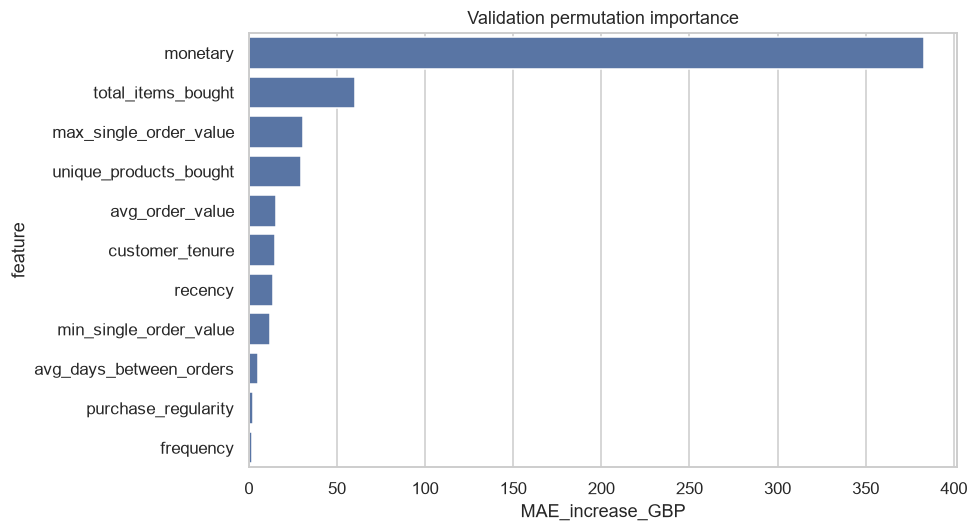

In [6]:
def candidate_mae(name):
    return next(r['MAE_GBP'] for r in rows if r['candidate']==name)
best_name=min(fitted,key=candidate_mae)
best=fitted[best_name]
def clipped_mae_scorer(estimator,X,y):
    return -mean_absolute_error(y,np.maximum(0.,estimator.predict(X)))
importance=permutation_importance(best['pipeline'],validation[FEATURES],validation['target'],
    scoring=clipped_mae_scorer,n_repeats=3,random_state=SEED,n_jobs=1)
importance_table=pd.DataFrame({'feature':FEATURES,'MAE_increase_GBP':importance.importances_mean,
    'repeat_std':importance.importances_std}).sort_values('MAE_increase_GBP',ascending=False)
print(importance_table.to_string(index=False))
n_positive=int(importance_table['MAE_increase_GBP'].gt(0).sum())
smaller_features=importance_table['feature'].head(max(5,n_positive)).tolist()
if len(smaller_features)<len(FEATURES):
    smaller=make_model(best['kind'],best['setting'])
    smaller.fit(train[smaller_features],train['target'])
    name=best_name+' / smaller features'
    rows.append({'candidate':name,'features':len(smaller_features),
        **metrics(validation['target'],predict_nonnegative(smaller,validation,smaller_features))})
    fitted[name]={'pipeline':smaller,'kind':best['kind'],'setting':best['setting'],'features':smaller_features}
best_name=min(fitted,key=candidate_mae)
best=fitted[best_name]
SELECTED_FEATURES=best['features']
BASELINE_VAL_MAE=mean_absolute_error(validation['target'],baseline(validation))
MODEL_VAL_MAE=candidate_mae(best_name)
VALIDATION_PASS=MODEL_VAL_MAE<BASELINE_VAL_MAE
print('Final validation comparison:')
print(pd.DataFrame(rows).sort_values('MAE_GBP').to_string(index=False))
print('Selected:',best_name)
print('Selected features:',SELECTED_FEATURES)
print('Removed features:',[f for f in FEATURES if f not in SELECTED_FEATURES])
print('Beats validation baseline:',VALIDATION_PASS)
fig,ax=plt.subplots(figsize=(9,5))
sns.barplot(data=importance_table,y='feature',x='MAE_increase_GBP',ax=ax)
ax.set_title('Validation permutation importance')
plt.tight_layout(); plt.show()

## 6. Evaluate once on the held-out test period
Settings and features are fixed. Report GBP errors, zero-spend and top-actual-spend groups, total predicted revenue, and top-20% revenue capture versus historical ranking. Ranking is a diagnostic for VIP targeting, not campaign uplift.
Do not use MAPE with zero targets. Report failed baseline checks honestly. A few seasonal windows and repeated known customers limit the evaluation.

               candidate    MAE_GBP    RMSE_GBP       R2
       Random Forest (5) 573.221345 2826.169576 0.509784
Historical rate baseline 544.656419 2670.479681 0.562307
Validation improvement GBP: 25.034952915648603
Test improvement GBP: -28.56492596852013
Zero future spend | customers: 1502 | model MAE GBP: 234.86209771374567 | baseline MAE GBP: 235.04505471870837
Positive future spend | customers: 1935 | model MAE GBP: 835.8650609368257 | baseline MAE GBP: 784.9852407945737
Top actual spenders | customers: 344 | model MAE GBP: 3147.5325583975296 | baseline MAE GBP: 2921.760128997093
Actual total GBP: 2662060.94
Predicted total GBP: 1731074.5884765591 | Baseline: 1846859.1225
Model top 20% customers: 688 | actual revenue captured GBP: 1775725.27 | share: 0.6670490683808313
Historical spending top 20% customers: 688 | actual revenue captured GBP: 1795053.2399999998 | share: 0.6743095971349174
Largest errors:
                target     predicted  absolute_error
Customer ID            

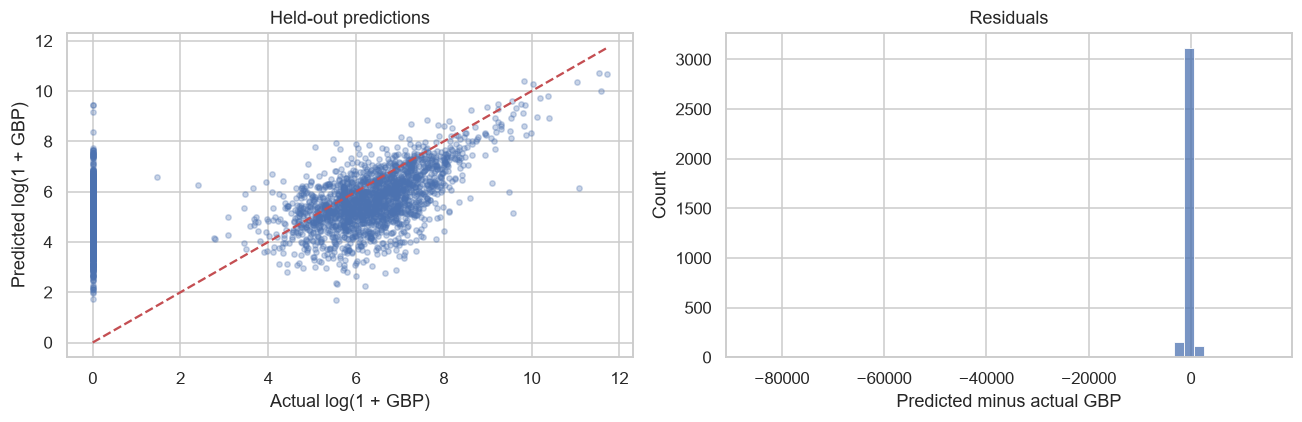

In [7]:
test_prediction=predict_nonnegative(best['pipeline'],test,SELECTED_FEATURES)
test_baseline=baseline(test)
TEST_METRICS=metrics(test['target'],test_prediction)
BASELINE_TEST_METRICS=metrics(test['target'],test_baseline)
TEST_PASS=TEST_METRICS['MAE_GBP']<BASELINE_TEST_METRICS['MAE_GBP']
print(pd.DataFrame([{'candidate':best_name,**TEST_METRICS},
    {'candidate':'Historical rate baseline',**BASELINE_TEST_METRICS}]).to_string(index=False))
print('Validation improvement GBP:',BASELINE_VAL_MAE-MODEL_VAL_MAE)
print('Test improvement GBP:',BASELINE_TEST_METRICS['MAE_GBP']-TEST_METRICS['MAE_GBP'])
zero=test['target'].eq(0).to_numpy()
high=test['target'].ge(test['target'].quantile(.90)).to_numpy()
for label,mask in [('Zero future spend',zero),('Positive future spend',~zero),('Top actual spenders',high)]:
    if mask.any():
        print(label,'| customers:',mask.sum(),'| model MAE GBP:',
            mean_absolute_error(test['target'].to_numpy()[mask],test_prediction[mask]),
            '| baseline MAE GBP:',mean_absolute_error(test['target'].to_numpy()[mask],test_baseline[mask]))
print('Actual total GBP:',test['target'].sum())
print('Predicted total GBP:',test_prediction.sum(),'| Baseline:',test_baseline.sum())
k=max(1,int(np.ceil(len(test)*TOP_FRACTION)))
total=test['target'].sum()
for label,scores in [('Model',test_prediction),('Historical spending',test['monetary'].to_numpy())]:
    captured=test['target'].iloc[np.argsort(-scores,kind='stable')[:k]].sum()
    print(label,'top 20% customers:',k,'| actual revenue captured GBP:',captured,
        '| share:',captured/total if total else np.nan)
errors=test[['target']].assign(predicted=test_prediction,absolute_error=np.abs(test['target']-test_prediction))
print('Largest errors:'); print(errors.nlargest(10,'absolute_error').to_string())
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(np.log1p(test['target']),np.log1p(test_prediction),s=12,alpha=.3)
limit=max(np.log1p(test['target']).max(),np.log1p(test_prediction).max())
axes[0].plot([0,limit],[0,limit],'r--')
axes[0].set(xlabel='Actual log(1 + GBP)',ylabel='Predicted log(1 + GBP)',title='Held-out predictions')
sns.histplot(test_prediction-test['target'].to_numpy(),bins=50,ax=axes[1])
axes[1].set(xlabel='Predicted minus actual GBP',title='Residuals')
plt.tight_layout(); plt.show()
print('Beats baseline on validation and test:',VALIDATION_PASS and TEST_PASS)

## 7. Verify raw-to-processed compatibility (read-only)
Processed data is never used for training. Validate its manifest/checksum and table relationships; reconstruct source transactions using ret: IDs. Preserve source strings, including .0 suffixes. Compare features, historical targets and predictions at every cutoff, with declared numerical tolerance.
Failure stops saving. The model cannot silently repair a transformation mismatch.

In [8]:
manifest=json.loads((PROCESSED/'manifest.json').read_text(encoding='utf-8'))
assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()==manifest['sources'][0]['sha256']
def read_table(name):
    frame=pd.read_csv(PROCESSED/name/f'{name}.csv',dtype=str,keep_default_na=False)
    assert len(frame)==manifest['output_counts'][name] and frame['id'].is_unique
    return frame
customers=read_table('customers')
products=read_table('products')
processed_orders=read_table('orders')
items=read_table('order_items')
assert customers['source_customer_id'].str.startswith('ret:').all()
assert products['source_product_id'].str.startswith('ret:').all()
assert processed_orders['source_order_id'].str.startswith('ret:').all()
joined=items.merge(processed_orders[['id','customer_id','source_order_id','order_date']],
    left_on='order_id',right_on='id',validate='many_to_one',suffixes=('','_order'))
joined=joined.merge(customers[['id','source_customer_id']],left_on='customer_id',right_on='id',
    validate='many_to_one',suffixes=('','_customer'))
joined=joined.merge(products[['id','source_product_id']],left_on='product_id',right_on='id',
    validate='many_to_one',suffixes=('','_product'))
assert len(joined)==len(items)
assert [Decimal(q)*Decimal(p) for q,p in zip(joined['quantity'],joined['unit_price'])]==joined['sales_value'].map(Decimal).tolist()
assert pd.to_datetime(joined['source_timestamp']).dt.strftime('%Y-%m-%d').tolist()==joined['order_date'].tolist()
reconstructed=pd.DataFrame({
    'Customer ID':joined['source_customer_id'].str.removeprefix('ret:'),
    'Invoice':joined['source_order_id'].str.removeprefix('ret:'),
    'StockCode':joined['source_product_id'].str.removeprefix('ret:'),
    'InvoiceDate':joined['source_timestamp'],'Quantity':joined['quantity'],'Price':joined['unit_price']})
processed_purchases=prepare_purchases(reconstructed,'Processed Retail')
assert len(processed_purchases)==len(purchases)
COMPATIBILITY_PASS=False
for cutoff in [*TRAIN_CUTOFFS,VAL_CUTOFF,TEST_CUTOFF,SOURCE_END]:
    a=customer_features(purchases,cutoff)
    b=customer_features(processed_purchases,cutoff)
    pd.testing.assert_frame_equal(a,b,check_exact=False,rtol=1e-10,atol=1e-8)
    np.testing.assert_allclose(predict_nonnegative(best['pipeline'],a,SELECTED_FEATURES),
        predict_nonnegative(best['pipeline'],b,SELECTED_FEATURES),rtol=1e-10,atol=1e-8)
    if cutoff<SOURCE_END:
        pd.testing.assert_series_equal(labelled_example(purchases,cutoff,False)['target'],
            labelled_example(processed_purchases,cutoff,False)['target'],check_exact=False,rtol=1e-10,atol=1e-8)
    print('Compatibility PASS:',cutoff.date(),'| customers:',len(a))
COMPATIBILITY_PASS=True
del joined,reconstructed,items
print('Raw/processed features, labels and evaluated-model predictions match.')

Processed Retail | input: 824364
  missing Customer ID : 0
  missing Invoice : 0
  missing StockCode : 0
  accounting/manual/test code : 1423
  invalid date : 0
  invalid/nonintegral quantity : 0
  invalid price : 0
  cancellation : 18744
  nonpositive quantity : 18744
  nonpositive price : 71
Distinct excluded rows: 19606 (reasons may overlap)
Retained purchase lines: 804758
Compatibility PASS: 2010-09-15 | customers: 3377
Compatibility PASS: 2010-12-14 | customers: 4024
Compatibility PASS: 2011-03-14 | customers: 3930
Compatibility PASS: 2011-06-12 | customers: 3982
Compatibility PASS: 2011-09-10 | customers: 3437
Compatibility PASS: 2011-12-09 | customers: 4028
Raw/processed features, labels and evaluated-model predictions match.


## 8. Refit, save and reload
Refit selected settings on all labelled snapshots after evaluation. Metrics describe the previously held-out configuration, not an independent test of this refitted pipeline.
Save an integration candidate only if baseline checks pass; otherwise save an explicitly experimental artifact that must not be activated. Compatibility failure blocks saving.
The artifact is a dictionary containing pipeline, features and metadata. Clip predictions as documented. Use matching library versions and load only trusted joblib files.

In [9]:
assert COMPATIBILITY_PASS
all_labelled=pd.concat([train,validation,test])
final_pipeline=make_model(best['kind'],best['setting'])
final_pipeline.fit(all_labelled[SELECTED_FEATURES],all_labelled['target'])
STATUS='integration_candidate' if VALIDATION_PASS and TEST_PASS else 'experimental_baseline_not_beaten'
feature_contract={
 'recency':'days since last purchase before cutoff',
 'frequency':'distinct purchase invoices',
 'monetary':'positive quantity times price summed in GBP',
 'avg_order_value':'monetary / frequency',
 'customer_tenure':'days since first observed purchase within fixed history',
 'total_items_bought':'sum of positive quantity',
 'unique_products_bought':'distinct source stock codes, including valid charge codes',
 'max_single_order_value':'maximum complete invoice total',
 'min_single_order_value':'minimum complete invoice total',
 'avg_days_between_orders':'mean consecutive invoice calendar-day gaps including same-day zeros; NaN with fewer than 2 orders',
 'purchase_regularity':'sample std of invoice day gaps ddof=1; NaN with fewer than 3 orders'}
metadata={
 'segment':'Future High-Value / CLV','target':'positive_purchase_revenue_next_90_days',
 'currency':'GBP','horizon_days':HORIZON_DAYS,'history_days':HISTORY_DAYS,
 'history_boundary':'[cutoff-history_days, cutoff)','outcome_boundary':'[cutoff, cutoff+90 days)',
 'date_grain':'source-local calendar days with midnight cutoffs',
 'transaction_policy':'valid keys/date/integral quantity/price; noncancelled invoices; quantity>0; price>0; repeats retained; postage/carriage included; accounting/manual/test codes excluded',
 'eligibility':'at least one valid purchase in history; otherwise insufficient_purchase_history',
 'excluded_stock_codes':['B','ADJUST','ADJUST2','BANK CHARGES','AMAZONFEE','CRUK','D','M','TEST001','TEST002'],
 'feature_contract':feature_contract,'model':best_name,'status':STATUS,
 'trained_at_utc':pd.Timestamp.now(tz='UTC').isoformat(),
 'source_sha256':manifest['sources'][0]['sha256'],'observation_cutoff':SOURCE_END.isoformat(),
 'train_cutoffs':[d.isoformat() for d in TRAIN_CUTOFFS],
 'validation_cutoff':VAL_CUTOFF.isoformat(),'test_cutoff':TEST_CUTOFF.isoformat(),
 'validation_MAE_GBP':float(MODEL_VAL_MAE),'baseline_validation_MAE_GBP':float(BASELINE_VAL_MAE),
 'held_out_configuration_metrics':{k:float(v) for k,v in TEST_METRICS.items()},
 'baseline_test_metrics':{k:float(v) for k,v in BASELINE_TEST_METRICS.items()},
 'metric_scope':'train-only fitted configuration; final pipeline refitted on all labelled snapshots',
 'raw_processed_compatibility':True,'final_training_snapshots':len(all_labelled),
 'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
             'scikit-learn':sklearn.__version__,'joblib':joblib.__version__},
 'limitations':['90-day revenue before refunds, not profit or unlimited lifetime',
    'historical giftware/wholesale population; other-store performance unverified',
    'few seasonal windows; customers recur across time; no cold-start predictions',
    'no causal campaign uplift or individual uncertainty estimate',
    'backend/database/dashboard integration not performed']}
artifact={'pipeline':final_pipeline,'features':SELECTED_FEATURES,'metadata':metadata,
    'prediction_policy':'np.maximum(0.0, pipeline.predict(frame[features])); required after loading'}
MODEL_PATH.parent.mkdir(parents=True,exist_ok=True)
joblib.dump(artifact,MODEL_PATH)
loaded=joblib.load(MODEL_PATH)
sample=test[SELECTED_FEATURES].head(20)
np.testing.assert_allclose(predict_nonnegative(final_pipeline,sample,SELECTED_FEATURES),
    predict_nonnegative(loaded['pipeline'],sample,loaded['features']),rtol=1e-12,atol=1e-8)
print('Saved:',MODEL_PATH)
print('Status:',STATUS,'| size MB:',round(MODEL_PATH.stat().st_size/1e6,2))
print('Reload predictions: PASS')
print('Environment:',metadata['versions'])
if STATUS!='integration_candidate':
    print('Baseline not beaten on both periods. Experimental artifact: investigate before activation.')
else:
    print('Baseline and compatibility passed. Backend end-to-end verification is still required.')

Saved: D:\CDP -FYP\backend\ml_models\clv_model.pkl
Status: experimental_baseline_not_beaten | size MB: 36.2
Reload predictions: PASS
Environment: {'python': '3.13.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'joblib': '1.6.0'}
Baseline not beaten on both periods. Experimental artifact: investigate before activation.


## 9. Current historical scoring — no future labels required
Score at the latest usable historical cutoff, not today's date. Include all identified source customers in results; explicitly mark insufficient-history customers. These are examples, not database updates or dashboard activation.

In [10]:
current_features=customer_features(purchases,SOURCE_END)
current_prediction=predict_nonnegative(loaded['pipeline'],current_features,loaded['features'])
ids=raw['Customer ID'].str.strip()
ids=pd.Index(sorted(ids[~ids.str.lower().isin({'','nan','none','null','<na>','nat'})].unique()),name='Customer ID')
current_results=pd.DataFrame(index=ids)
current_results['observation_date']=SOURCE_END.date().isoformat()
current_results['predicted_90_day_revenue_GBP']=pd.Series(current_prediction,index=current_features.index)
current_results['status']=np.where(current_results['predicted_90_day_revenue_GBP'].notna(),
    'scored_'+STATUS,'insufficient_purchase_history')
print('All identified customers:',len(current_results))
print(current_results['status'].value_counts().to_string())
print('Highest predictions (display rounding only):')
print(current_results.sort_values('predicted_90_day_revenue_GBP',ascending=False).head(10).round(2).to_string())
print('Insufficient-history examples:')
print(current_results[current_results['status'].eq('insufficient_purchase_history')].head().to_string())
assert len(current_results)==len(ids)
assert np.isfinite(current_prediction).all() and (current_prediction>=0).all()
print('Scoring checks: PASS. No feature or prediction CSVs were written.')

All identified customers: 5942
status
scored_experimental_baseline_not_beaten    4028
insufficient_purchase_history              1914
Highest predictions (display rounding only):
            observation_date  predicted_90_day_revenue_GBP                                   status
Customer ID                                                                                        
17450.0           2011-12-09                      62897.90  scored_experimental_baseline_not_beaten
14646.0           2011-12-09                      61820.27  scored_experimental_baseline_not_beaten
18102.0           2011-12-09                      61591.18  scored_experimental_baseline_not_beaten
12415.0           2011-12-09                      43059.37  scored_experimental_baseline_not_beaten
14156.0           2011-12-09                      40292.62  scored_experimental_baseline_not_beaten
14911.0           2011-12-09                      30603.26  scored_experimental_baseline_not_beaten
14096.0           201

## Application contract
- Reproduce saved history windows, eligibility, purchase filters and feature formulas exactly. Keep undefined intervals missing until the saved pipeline imputes them.
- Use Retail relationships and source identity; do not combine unrelated customer populations or unsupported currencies.
- Supply selected feature columns in saved order. Reject missing columns, infinities, invalid histories and unsupported currency. Insufficient history is unavailable, not zero.
- Load the trusted dictionary artifact with matching dependency versions. Predict using pipeline and features, then apply its nonnegative policy.
- Monetary predictions need suitable storage: do not place GBP into probability-style customer_segments.score. VIP membership needs a separate product rule.
- No backend endpoint, database, campaign, dashboard, dependency file, transformation or ignore rule is changed. The current ignore rule permits only churn_model.pkl; publishing CLV needs a separately authorized change.
- Even passing evaluation does not establish production readiness. Check backend feature calculations and inference end to end. Failed baseline checks leave an experimental artifact.
References: [UCI dataset](https://archive.ics.uci.edu/dataset/502/online%2Bretail%2Bii), [scikit-learn pitfalls](https://scikit-learn.org/stable/common_pitfalls.html), [persistence](https://scikit-learn.org/stable/model_persistence.html), [forest/boosting comparison](https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_hist_grad_boosting_comparison.html).
Project references: CLV segment notes, segment/schema mapping, KPI mapping, transformation contract v2, retail.py and processed Retail manifest.
Reload prediction comparison uses rtol=1e-12 and atol=1e-8 GBP to allow harmless floating-point summation differences from parallel forest prediction. No material monetary discrepancy is accepted.